# Assignment 3 — Utility-Based Resource Selection Agent

**Objective:** Design a utility-based agent that chooses resources to maximize total score.

The agent evaluates available resources using utility scores and repeatedly selects the resource that provides the highest utility.

## Basic idea

A utility-based agent compares different choices and selects the option that gives the highest benefit.

In this simulation:

- Each resource has a utility score.
- The agent has a limited collection budget.
- At each step, it chooses the available resource with the highest utility.
- The selected resource is removed from the available resources.
- The process continues until the budget is used.

In [1]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Create the available resources

Each resource is assigned a utility score. A higher score means the resource is more valuable to the agent.

In [2]:
resources = {
    "Food": 20,
    "Water": 15,
    "Energy": 10,
    "Medicine": 25,
    "Tools": 12
}

print("Available Resources")
print("-------------------")

for resource, utility in resources.items():
    print(f"{resource:<10} -> Utility: {utility}")

Available Resources
-------------------
Food       -> Utility: 20
Water      -> Utility: 15
Energy     -> Utility: 10
Medicine   -> Utility: 25
Tools      -> Utility: 12


## Step 2 — Create the utility-based decision function

The agent checks every available resource and remembers the one with the highest utility.

In [3]:
def choose_resource(resources):
    best_resource = None
    highest_utility = -1

    for resource, utility in resources.items():
        if utility > highest_utility:
            highest_utility = utility
            best_resource = resource

    return best_resource, highest_utility

## Step 3 — Make a single decision

Before selecting multiple resources, we can test the agent's basic decision-making.

In [4]:
chosen_resource, utility = choose_resource(resources)

print("Agent selected:", chosen_resource)
print("Utility gained:", utility)

Agent selected: Medicine
Utility gained: 25


## Step 4 — Give the agent a limited budget

The agent can collect only three resources. After choosing one, that resource is removed, so the next decision is made using the remaining resources.

In [5]:
resources = {
    "Food": 20,
    "Water": 15,
    "Energy": 10,
    "Medicine": 25,
    "Tools": 12
}

budget = 3
selected = []
total_score = 0

for step in range(1, budget + 1):
    best_resource, utility = choose_resource(resources)

    selected.append(best_resource)
    total_score += utility

    print(f"Step {step}: {best_resource} selected (Utility = {utility})")

    # Remove the selected resource before the next decision
    del resources[best_resource]

print("\nSelected resources:", selected)
print("Total utility score:", total_score)

Step 1: Medicine selected (Utility = 25)
Step 2: Food selected (Utility = 20)
Step 3: Water selected (Utility = 15)

Selected resources: ['Medicine', 'Food', 'Water']
Total utility score: 60


## Step 5 — Visualize the utility values

This graph shows why the agent chooses certain resources first. The resource with the highest utility is the most attractive choice.

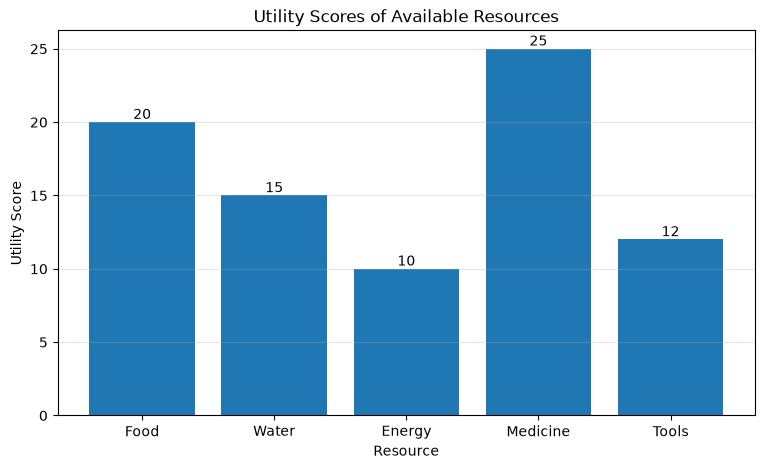

In [6]:
resources = {
    "Food": 20,
    "Water": 15,
    "Energy": 10,
    "Medicine": 25,
    "Tools": 12
}

names = list(resources.keys())
scores = list(resources.values())

plt.figure(figsize=(9, 5))
bars = plt.bar(names, scores)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(score),
        ha="center",
        va="bottom"
    )

plt.title("Utility Scores of Available Resources")
plt.xlabel("Resource")
plt.ylabel("Utility Score")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Step 6 — Animated resource selection

This simulation shows the agent selecting resources one by one. The highest-utility resource is selected at every step and then removed.

In [7]:
resources = {
    "Food": 20,
    "Water": 15,
    "Energy": 10,
    "Medicine": 25,
    "Tools": 12
}

budget = 3
selected = []
total_score = 0

for step in range(1, budget + 1):
    best_resource, best_utility = choose_resource(resources)

    clear_output(wait=True)

    names = list(resources.keys())
    scores = list(resources.values())

    plt.figure(figsize=(9, 5))
    bars = plt.bar(names, scores)

    # Highlight the resource the agent is about to select
    for bar, name in zip(bars, names):
        if name == best_resource:
            bar.set_linewidth(3)

    plt.title(
        f"Utility-Based Agent — Step {step}\n"
        f"Choosing {best_resource} (Utility = {best_utility})"
    )
    plt.xlabel("Available Resource")
    plt.ylabel("Utility Score")
    plt.ylim(0, 30)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    time.sleep(1.2)

    selected.append(best_resource)
    total_score += best_utility
    del resources[best_resource]

clear_output(wait=True)

print("Selection completed.")
print("Selected resources:", selected)
print("Total utility score:", total_score)

Selection completed.
Selected resources: ['Medicine', 'Food', 'Water']
Total utility score: 60


## Step 7 — Show how the total utility increases

This graph shows the cumulative score after each resource is selected.

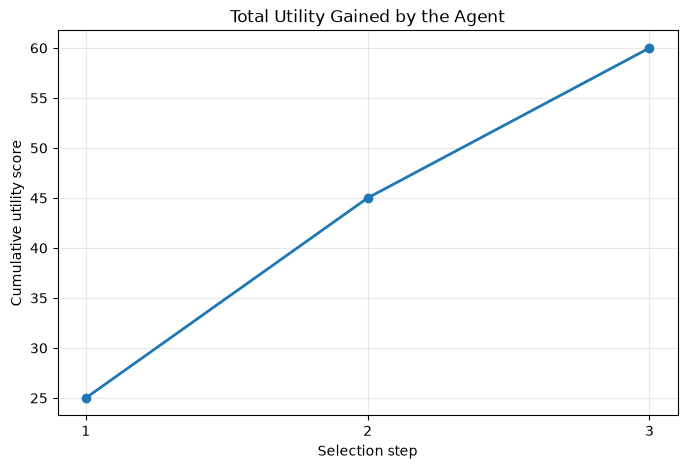

In [8]:
utilities = [25, 20, 15]
steps = [1, 2, 3]
cumulative_scores = []
running_total = 0

for utility in utilities:
    running_total += utility
    cumulative_scores.append(running_total)

plt.figure(figsize=(8, 5))
plt.plot(steps, cumulative_scores, marker="o", linewidth=2)
plt.xticks(steps)
plt.xlabel("Selection step")
plt.ylabel("Cumulative utility score")
plt.title("Total Utility Gained by the Agent")
plt.grid(True, alpha=0.3)
plt.show()

## Step 8 — Final simulation summary

In [9]:
print("Utility-Based Agent")
print("-------------------")
print("Selection budget:", budget)
print("Selected resources:", selected)
print("Total utility score:", total_score)
print("Best first choice:", selected[0])

Utility-Based Agent
-------------------
Selection budget: 3
Selected resources: ['Medicine', 'Food', 'Water']
Total utility score: 60
Best first choice: Medicine


## Final result

The utility-based agent evaluates the available options and repeatedly chooses the resource with the highest utility. With the given values and a budget of three resources, it selects **Medicine, Food, and Water**, giving a total utility score of **60**.